# Fuzzy Bern Guide – fuzzy control system

Mercan Esen  

This notebook applies the **fuzzy control system** approach from `01_FuzzyControlSystem.ipynb` to our group project domain: recommending a local tour guide in Bern to a tourist.

Booking sites use hard yes or no filters, so a great guide at 55 CHF disappears. Here, every tourist guide pair gets a suitability score from 0 to 100 instead.

*AI use: I used Claude to improve my code.This notebook builds on our group’s mid-term code, which was written with help from Claude (Anthropic). I also used Claude to improve the code,*

In [14]:
!pip install -q scikit-fuzzy networkx

## Where do these results come from?

- **Tourists:** *I asked these questions to my friends:*

QUESTIONS
*   How many hours do you have for a guided tour in Bern?
*   Which topics interest you? (history & architecture, food & drinks, art & museums, nature, nightlife)
*   What is your budget per person for one tour (CHF)?
*   Which language do you prefer? Which other languages are also okay?

 **The main purpose of these questions was to gather the following information: areas of interest, available times, budget, and languages**

*then I converted their answers into numbers*

- **Guides:** invented sample data

In [15]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

guides = {
    "Anna (history)":        dict(topics=["history"],                   hours=2.5, price=55,  langs=["de", "en"]),
    "Luca (food)":           dict(topics=["food"],                      hours=3,   price=45,  langs=["it", "en", "es"]),
    "Marie (art)":           dict(topics=["art", "history"],            hours=3,   price=70,  langs=["fr", "en"]),
    "Jonas (full day)":      dict(topics=["food", "nature", "history"], hours=7,   price=120, langs=["de", "en"]),
    "Sofia (tapas)":         dict(topics=["food", "nightlife"],         hours=4,   price=58,  langs=["es", "pt", "en"]),
    "Peter (Einstein)":      dict(topics=["history"],                   hours=1.5, price=35,  langs=["de", "fr"]),
    "Defne (Bern by night)": dict(topics=["nightlife", "food"],         hours=3,   price=40,  langs=["tr", "de", "en"]),
    "Wei (highlights)":      dict(topics=["history", "nature"],         hours=2,   price=30,  langs=["zh", "en"]),
}

tourists = {
    "Elif":   dict(topics=["food", "nature"],               hours=8, budget=200, langs=["tr", "en"]),
    "Bill":   dict(topics=["food", "nightlife"],            hours=5, budget=20,  langs=["es", "en"]),
    "Asli":   dict(topics=["history", "food", "nightlife"], hours=8, budget=50,  langs=["tr", "en"]),
    "Sali":   dict(topics=["food", "nightlife"],            hours=2, budget=50,  langs=["fr", "en"]),
    "Nicola": dict(topics=["food", "nature", "art"],        hours=8, budget=60,  langs=["en"]),
}

##  Fuzzify and membership functions


# I have 3 inputs (antecedents)
- **interest:** How many of the tourists topics the guide covers (0 to 1)
- **price:** guide price divided by the tourists budget
- **time:** tour length divided by the tourists free time

I use ratios so the rules work for every tourist.
# And 1 output (consequent)
- **score:** The output is a score from 0 to 100.

I chose the limits myself. People told me aroun 50 chf, so a price a bit over the budget is still partly ok. Time is stricter, because you can't get more time

In standard programming, the logic would say, “60 > 50, so it’s expensive,” and skip the tour. A membership function, on the other hand, can say, “somewhat affordable, somewhat expensive.” That’s the whole point of fuzzy logic

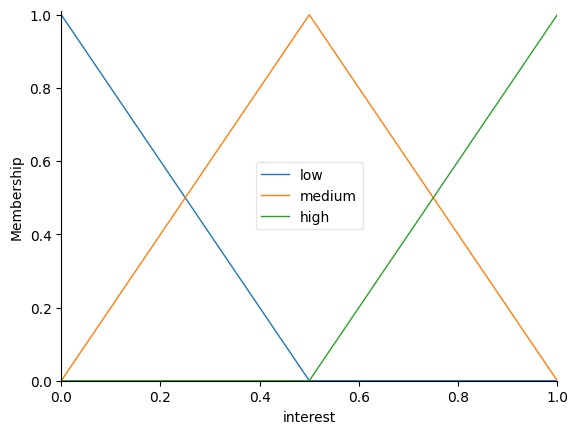

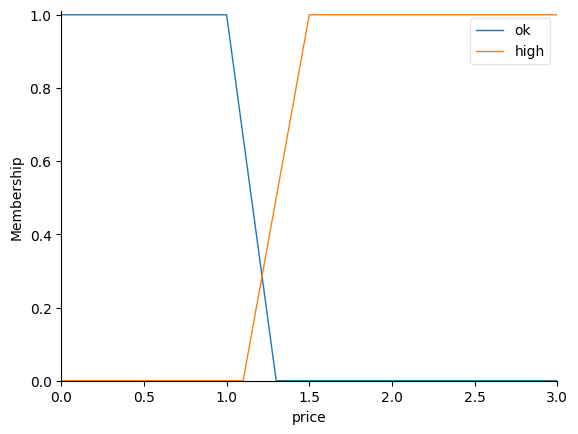

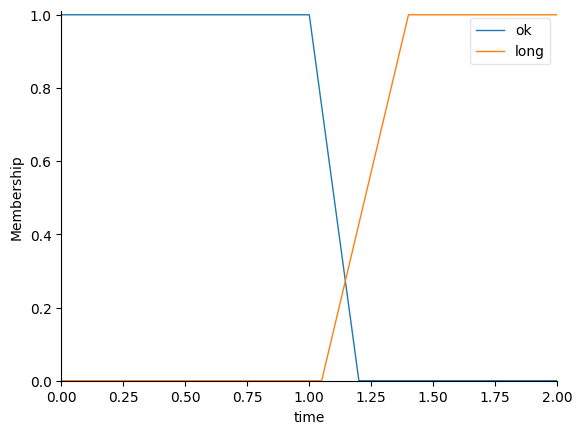

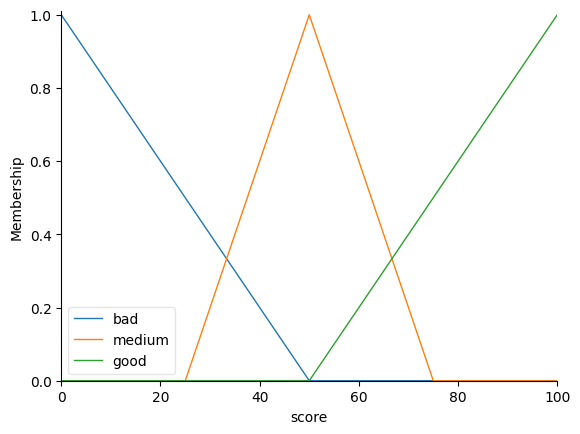

In [16]:
interest = ctrl.Antecedent(np.arange(0, 1.01, 0.01), "interest")
price    = ctrl.Antecedent(np.arange(0, 3.01, 0.01), "price")
time     = ctrl.Antecedent(np.arange(0, 2.01, 0.01), "time")
score    = ctrl.Consequent(np.arange(0, 101, 1), "score")

interest["low"]    = fuzz.trimf(interest.universe, [0, 0, 0.5])
interest["medium"] = fuzz.trimf(interest.universe, [0, 0.5, 1])
interest["high"]   = fuzz.trimf(interest.universe, [0.5, 1, 1])

price["ok"]   = fuzz.trapmf(price.universe, [0, 0, 1, 1.3])
price["high"] = fuzz.trapmf(price.universe, [1.1, 1.5, 3, 3])

time["ok"]   = fuzz.trapmf(time.universe, [0, 0, 1, 1.2])
time["long"] = fuzz.trapmf(time.universe, [1.05, 1.4, 2, 2])

score["bad"]    = fuzz.trimf(score.universe, [0, 0, 50])
score["medium"] = fuzz.trimf(score.universe, [25, 50, 75])
score["good"]   = fuzz.trimf(score.universe, [50, 100, 100])

interest.view(); price.view(); time.view(); score.view()

## Rules

- if interest high and price is ok and time is ok then score is good
- if interest medium and price ok and time ok then score is medium
- if interest is low then score is bad
- if price is high then score is bad
- if time is long then score is bad

- **first and second rulse**: if price and time are fine the interest match decides the score
- **other rules:** "deal-breakers" one problem alone is enough to lower the score. No matter how interested a tourist is, a 7-hour tour is useless for someone with 3 hours.
- **In fuzzy logic, AND means minimum:**  So if one condition is weak for example the price, the whole rule is weak, even if the other conditions are strong.

In [17]:
rules = [
    ctrl.Rule(interest["high"] & price["ok"] & time["ok"], score["good"]),
    ctrl.Rule(interest["medium"] & price["ok"] & time["ok"], score["medium"]),
    ctrl.Rule(interest["low"], score["bad"]),
    ctrl.Rule(price["high"], score["bad"]),
    ctrl.Rule(time["long"], score["bad"]),
]
system = ctrl.ControlSystem(rules)

def match(t, g):
    """Suitability score (0-100) of guide g for tourist t."""
    if not set(t["langs"]) & set(g["langs"]):  # no shared language -> no match
        return 0
    sim = ctrl.ControlSystemSimulation(system)
    sim.input["interest"] = len(set(t["topics"]) & set(g["topics"])) / len(t["topics"])
    sim.input["price"] = min(g["price"] / t["budget"], 3)
    sim.input["time"] = min(g["hours"] / t["hours"], 2)
    sim.compute()
    return sim.output["score"]

##  One example in detail: Asli and Defne
Asli is tourist, Defne is guide

Asli wants history, food and nightlife and she has 8 h and 50 CHF. Defne offers nightlife and food (3 h, 40 CHF) and speaks Turkish (We dont take the language account because language isnt a fuzzy input).
- Inputs: interest = 2/3 ≈ 0.67, price = 40/50 = 0.8, time = 3/8 ≈ 0.38. The plot shows the aggregated output and the centroid.

Asli - Defne: 60.7


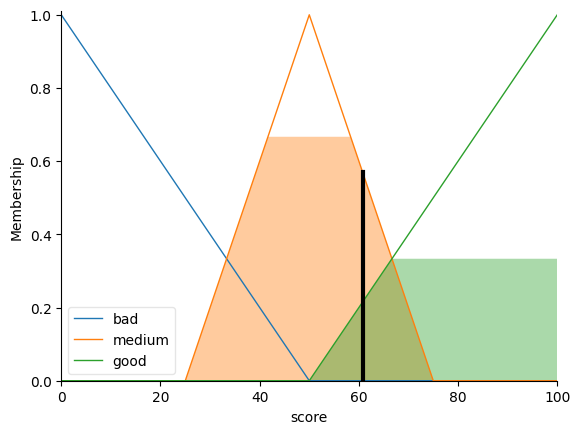

In [18]:
sim = ctrl.ControlSystemSimulation(system)
sim.input["interest"] = 2/3
sim.input["price"] = 40/50
sim.input["time"] = 3/8
sim.compute()
print(f"Asli - Defne: {sim.output['score']:.1f}")
score.view(sim=sim)

##  Results: top 3 guides per tourist

In [19]:
for name, t in tourists.items():
    ranking = sorted(((match(t, g), gname) for gname, g in guides.items()), reverse=True)
    print(f"\n{name}  ({', '.join(t['topics'])} | {t['hours']}h | {t['budget']} CHF)")
    for s, gname in ranking[:3]:
        print(f"   {s:5.1f}  {gname}")


Elif  (food, nature | 8h | 200 CHF)
    83.3  Jonas (full day)
    50.0  Wei (highlights)
    50.0  Sofia (tapas)

Bill  (food, nightlife | 5h | 20 CHF)
    16.7  Wei (highlights)
    16.7  Sofia (tapas)
    16.7  Marie (art)

Asli  (history, food, nightlife | 8h | 50 CHF)
    60.7  Defne (Bern by night)
    56.2  Sofia (tapas)
    39.3  Wei (highlights)

Sali  (food, nightlife | 2h | 50 CHF)
    16.7  Wei (highlights)
    16.7  Sofia (tapas)
    16.7  Peter (Einstein)

Nicola  (food, nature, art | 8h | 60 CHF)
    39.3  Wei (highlights)
    39.3  Sofia (tapas)
    39.3  Luca (food)


## Full table: every tourist vs. every guide

In [20]:
import pandas as pd

table = pd.DataFrame({g: {t: round(match(tourists[t], guides[g])) for t in tourists} for g in guides})
table.style.background_gradient(cmap="Blues", vmin=0, vmax=100)

,Anna (history),Luca (food),Marie (art),Jonas (full day),Sofia (tapas),Peter (Einstein),Defne (Bern by night),Wei (highlights)
Elif,17,50,17,83,50,0,50,50
Bill,17,17,17,17,17,0,17,17
Asli,39,39,18,17,56,0,61,39
Sali,17,17,17,17,17,17,17,17
Nicola,17,39,37,17,39,0,39,39


##  Experiment: how strict should the budget be?

I kept the interest, the time and the budget (50 CHF) the same and only changed the price of the tour. The budget is what the tourist wants, so it stays the same, but the price belongs to the tour, so I changed it to see how different tours are scored for the same tourist. When the price was close to the budget, the score was almost the same as a good score. When the price went higher, the score went down slowly, not suddenly. This is because fuzzy logic uses membership degrees between 0 and 1, like 0.33 or 0.75, instead of only yes or no. This is the main difference from classic programs.


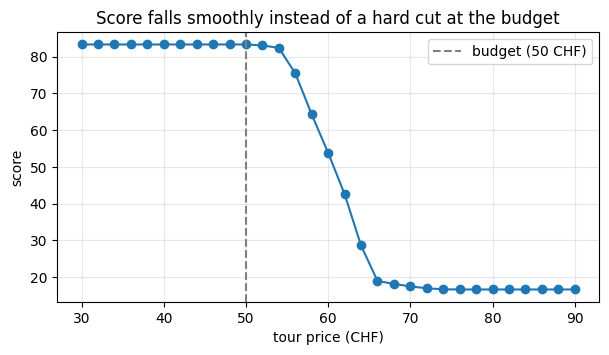

In [21]:
import matplotlib.pyplot as plt

prices = np.arange(30, 91, 2)
scores = []
for p in prices:
    s = ctrl.ControlSystemSimulation(system)
    s.input["interest"] = 1.0
    s.input["price"] = p / 50
    s.input["time"] = 0.5
    s.compute()
    scores.append(s.output["score"])

plt.figure(figsize=(7, 3.5))
plt.plot(prices, scores, marker="o")
plt.axvline(50, color="grey", linestyle="--", label="budget (50 CHF)")
plt.xlabel("tour price (CHF)"); plt.ylabel("score"); plt.legend(); plt.grid(alpha=.3)
plt.title("Score falls smoothly instead of a hard cut at the budget")
plt.show()

## Observations

- **Elif – Jonas (83)** is the best match: the tour fits her interests, time and budget.
- **Asli – Defne (61):** two of three interests covered, and a shared language (Turkish).
- **Bill and Sali** score low everywhere: Bill's budget (20 CHF) and Sali's time (2 h) are too small for the sample tours.
- **The highest possible score is about 83**, not 100: centroid defuzzification never reaches the edge of the "good" triangle.
- The experiment shows the main idea: the score drops gradually from about 83 at 50 CHF to about 54 at 60 CHF and 17 at 70 CHF, instead of falling to zero at 51 CHF.

**Next steps:** I already asked the tourists for their budget, but I did not ask how much over their budget they would still accept. So I guessed this limit myself (30% over budget, the end of the “ok” price membership function). Next, I want to ask people: “Your budget is 50 CHF. Up to what price would you still book a tour?” With their answers, I can set this limit of the membership function based on real data instead of my guess. I also want to use real guide data instead of my sample guides.